In [24]:
risk_map = {
    "Low": ["Low"],
    "Moderate": ["Moderate"],
    "High": ["Moderately High", "High", "Very High"],
}

def recommend(appetite):
    """Top 3 funds by Sharpe ratio for the given risk appetite (Low, Moderate, High)."""
    grades = risk_map[appetite]
    pool = perf[perf["risk_grade"].isin(grades)]
    top3 = pool.sort_values("sharpe_ratio", ascending=False).head(3)
    return top3[["scheme_name", "category", "risk_grade", "sharpe_ratio", "return_3yr_pct"]]

for level in ["Low", "Moderate", "High"]:
    print(f"\nRisk appetite: {level}")
    print(recommend(level).round(2).to_string(index=False))


Risk appetite: Low
                             scheme_name category risk_grade  sharpe_ratio  return_3yr_pct
ICICI Pru Liquid Fund - Regular - Growth     Debt        Low          7.68            7.68
    Kotak Liquid Fund - Regular - Growth     Debt        Low          6.18            6.18
     ABSL Liquid Fund - Regular - Growth     Debt        Low          5.14            5.14

Risk appetite: Moderate
                                  scheme_name category risk_grade  sharpe_ratio  return_3yr_pct
    HDFC Top 100 Fund - Regular Plan - Growth   Equity   Moderate          1.06           14.84
Mirae Asset Large Cap Fund - Regular - Growth   Equity   Moderate          1.06           14.81
    ICICI Pru Bluechip Fund - Direct - Growth   Equity   Moderate          1.03           14.41

Risk appetite: High
                                      scheme_name category      risk_grade  sharpe_ratio  return_3yr_pct
ICICI Pru Value Discovery Fund - Regular - Growth   Equity Moderately High       

## Key EDA Findings (10 insights)

1. **NAV trend:** All 40 schemes moved in the same general direction from 2022 to 2026, but the range between the best and worst funds widened over time. *(chart_01_nav_trend.png)*

2. **Top 5 schemes:** SBI Small Cap peaked in 2023 and fell back in 2024, while Mirae Large Cap was the strongest performer by 2026. *(chart_02_top5_highlight.png)*

3. **AUM growth:** SBI Mutual Fund's AUM roughly doubled from 2022 to 2025 and remained the largest fund house, at about 22% of the top 8 houses' total in 2025. *(chart_03_aum_growth.png)*

4. **SIP inflow:** Monthly SIP inflow rose from ₹11,517 crore in January 2022 to ₹31,002 crore in December 2025, about 2.7 times higher. *(chart_04_sip_inflow.png)*

5. **SIP vs Nifty 50:** The correlation between monthly SIP inflow and the Nifty 50 month-end close was -0.21, a weak relationship. *(chart_05_sip_vs_nifty.png)*

6. **Folio growth:** Industry folios grew from 13.26 crore to 26.12 crore (about 2 times), and equity's share stayed at about 70%. *(chart_06_folio_growth.png)*

7. **Sector allocation:** Banking is the largest sector at 19.3% of holdings, and the top four sectors together account for 52.4%. *(chart_07_sector_allocation.png)*

8. **Risk vs return:** Small Cap (25% volatility, 21.7% 3-year return) and Mid Cap (19%, 16.6%) delivered higher returns with higher risk. *(chart_13_risk_return.png)*

9. **Investors:** The 26-35 age group is the largest among 5,000 investors (40.7%), and SIP accounts for 60% of transactions. *(chart_14_investor_demographics.png)*

10. **Maximum drawdown:** Average drawdown was between -2.3% and -6.0% for debt and liquid categories, but between -15.8% and -33.2% for equity categories. *(chart_16_drawdown_by_category.png)*

In [1]:
perf = pd.read_sql_query("""
    SELECT p.amfi_code, f.scheme_name, f.category, p.risk_grade,
           p.sharpe_ratio, p.return_3yr_pct, p.std_dev_ann_pct
    FROM fact_performance p
    JOIN dim_fund f ON f.amfi_code = p.amfi_code
""", conn)
print(perf["risk_grade"].value_counts())

NameError: name 'pd' is not defined

In [ ]:
for lag in [-2, -1, 0, 1, 2]:
    shifted = nifty_ret.shift(lag)
    c = pd.concat([live_ret, shifted], axis=1, join="inner").dropna()
    print(f"lag {lag:+d}: corr = {c.iloc[:, 0].corr(c.iloc[:, 1]):.3f}  (n={len(c)})")

lag -2: corr = -0.007  (n=1061)
lag -1: corr = -0.009  (n=1061)
lag +0: corr = 0.067  (n=1062)
lag +1: corr = -0.004  (n=1061)
lag +2: corr = -0.026  (n=1060)


In [ ]:
live = pd.read_csv(find_raw("nav_sbi_bluechip"))
live["date"] = pd.to_datetime(live["date"])
live_ret = live.sort_values("date").set_index("date")["nav"].pct_change().dropna()

both = pd.concat([live_ret, nifty_ret], axis=1, join="inner").dropna()
both.columns = ["sbi_live", "nifty"]
print("Common dates:", len(both))
print("SBI Bluechip (live mfapi) vs Nifty corr:", round(both["sbi_live"].corr(both["nifty"]), 3))

Common dates: 1062
SBI Bluechip (live mfapi) vs Nifty corr: 0.067


In [ ]:
mirae = nav[nav["amfi_code"] == 148567].sort_values("date").set_index("date")["nav"].pct_change()
nav_all = nav.sort_values("date").copy()
nav_all["ret"] = nav_all.groupby("amfi_code")["nav"].pct_change()
avg_all = nav_all.groupby("date")["ret"].mean()

both = pd.concat([mirae, nifty_ret], axis=1, join="inner").dropna()
both.columns = ["mirae", "nifty"]
print("Common dates:", len(both))
print("Mirae vs Nifty corr:", round(both["mirae"].corr(both["nifty"]), 3))
print("Mirae vs average of 40 funds:", round(mirae.corr(avg_all), 3))
print("Nifty vs average of 40 funds:", round(nifty_ret.corr(avg_all), 3))
print(both.head(3))

Common dates: 1149
Mirae vs Nifty corr: -0.026
Mirae vs average of 40 funds: 0.103
Nifty vs average of 40 funds: 0.005
               mirae     nifty
date                          
2022-01-04  0.019318  0.011253
2022-01-05 -0.003939  0.008220
2022-01-06  0.011892  0.002437


In [ ]:
bench = pd.read_csv(find_raw("benchmark"))
print(bench.shape)

(8050, 3)


In [ ]:
# 1. Nifty 50 ka daily return
nifty = bench[bench["index_name"] == "NIFTY50"].copy()
nifty["date"] = pd.to_datetime(nifty["date"])
nifty = nifty.set_index("date")["close_value"].sort_index()
nifty_ret = nifty.pct_change().dropna()

te_rows = []
for code in top5:
    # 2. Fund ka daily return
    fund = nav[nav["amfi_code"] == code].sort_values("date").set_index("date")["nav"]
    fund_ret = fund.pct_change().dropna()

    # 3. Dono ko same dates par match karna, aur farak nikalna
    both = pd.concat([fund_ret, nifty_ret], axis=1, join="inner").dropna()
    both.columns = ["fund", "nifty"]
    diff = both["fund"] - both["nifty"]

    # 4. Standard deviation ko annualise karna (252 trading days)
    te = diff.std() * np.sqrt(252) * 100

    te_rows.append({
        "scheme": names_map[code],
        "tracking_error_pct": round(te, 2),
        "correlation_with_nifty": round(both["fund"].corr(both["nifty"]), 3),
        "days_matched": len(both),
    })

te_df = pd.DataFrame(te_rows)
print(te_df.to_string(index=False))
te_df.to_csv("reports/tracking_error.csv", index=False)

                scheme  tracking_error_pct  correlation_with_nifty  days_matched
         SBI Small Cap               27.80                   0.038          1149
      ICICI Pru Midcap               23.31                  -0.012          1149
       Mirae Large Cap               19.40                  -0.026          1149
Mirae Tax Saver (ELSS)               21.94                  -0.007          1149
         DSP Small Cap               27.18                   0.069          1149


In [ ]:
fund_info = pd.read_sql_query("SELECT amfi_code, scheme_name, category FROM dim_fund", conn)

hold["sector_weight"] = hold["market_value_cr"] / hold.groupby("amfi_code")["market_value_cr"].transform("sum")

hhi = (hold.groupby(["amfi_code", "sector"])["sector_weight"].sum()
           .pow(2).groupby(level=0).sum()
           .rename("hhi"))

hhi_df = (hhi.to_frame()
             .join(hold.groupby("amfi_code")["sector"].nunique().rename("sectors"))
             .join(fund_info.set_index("amfi_code")))
equity = hhi_df[hhi_df["category"].str.contains("Equity|Cap|Flexi|Value|ELSS|Sectoral|Thematic|Mid", case=False, na=False)]
hhi_df = hhi_df.sort_values("hhi", ascending=False)

print(hhi_df.head(10)[["scheme_name", "category", "sectors", "hhi"]].round(3).to_string())
print("\nEquity funds (matched by category):", len(equity))
print("Median HHI, equity:", round(equity["hhi"].median(), 3))
print("Median HHI, all:", round(hhi_df["hhi"].median(), 3))

                                                  scheme_name category  sectors    hhi
amfi_code                                                                             
125497               HDFC Top 100 Fund - Direct Plan - Growth   Equity        7  0.283
119094                    Axis Midcap Fund - Regular - Growth   Equity        6  0.258
118633          Nippon India Large Cap Fund - Direct - Growth   Equity        7  0.256
149322             DSP Top 100 Equity Fund - Regular - Growth   Equity        7  0.248
101207                 ABSL Small Cap Fund - Regular - Growth   Equity        6  0.243
102887                  UTI Flexi Cap Fund - Regular - Growth   Equity        6  0.241
118635                         Nippon India ETF Nifty 50 BeES   Equity        6  0.234
119551              SBI Bluechip Fund - Regular Plan - Growth   Equity        8  0.233
149323                     DSP Midcap Fund - Regular - Growth   Equity        7  0.225
100033     HDFC Mid-Cap Opportunities Fund 

In [ ]:
fund_info = pd.read_sql_query("SELECT amfi_code, scheme_name, category FROM dim_fund", conn)

In [ ]:
hold = pd.read_csv(find_raw("portfolio"))
print(find_raw("portfolio").name, hold.shape)

1788499982117-e3d6ab98-09_portfolio_holdings.csv (322, 8)


In [ ]:
from pathlib import Path
RAW = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")

def find_raw(keyword):
    return [f for f in RAW.glob("*.csv") if keyword in f.name.lower()][0]

In [ ]:
hold = pd.read_sql_query("""
    SELECT h.amfi_code, h.sector, h.market_value_cr, f.scheme_name, f.category
    FROM portfolio_holdings h
    JOIN dim_fund f ON f.amfi_code = h.amfi_code
""", conn)

DatabaseError: Execution failed on sql '
    SELECT h.amfi_code, h.sector, h.market_value_cr, f.scheme_name, f.category
    FROM portfolio_holdings h
    JOIN dim_fund f ON f.amfi_code = h.amfi_code
': no such table: portfolio_holdings

In [ ]:
hold = pd.read_csv(find_raw("portfolio"))
hold["sector_weight"] = hold["market_value_cr"] / hold.groupby("amfi_code")["market_value_cr"].transform("sum")

hhi = (hold.groupby(["amfi_code", "sector"])["sector_weight"].sum()
           .pow(2).groupby(level=0).sum()
           .rename("hhi"))

hhi_df = (hhi.to_frame()
             .join(hold.groupby("amfi_code")["sector"].nunique().rename("sectors"))
             .join(pd.read_sql_query("SELECT amfi_code, scheme_name, category FROM dim_fund", conn)
                     .set_index("amfi_code")))
equity = hhi_df[hhi_df["category"].str.contains("Equity|Cap|Flexi|Value|ELSS|Sectoral|Thematic|Mid", case=False, na=False)]
hhi_df = hhi_df.sort_values("hhi", ascending=False)

print(hhi_df.head(10).round(3).to_string())
print("\nEquity funds (matched by category):", len(equity))
print("Median HHI, equity:", round(equity["hhi"].median(), 3))
print("Median HHI, all:", round(hhi_df["hhi"].median(), 3))

NameError: name 'find_raw' is not defined

In [ ]:
for thr in [35, 70, 90]:
    n = (gap_summary["avg_gap_days"] > thr).sum()
    print(f"Threshold {thr} days: at-risk = {n} ({n / len(gap_summary) * 100:.1f}%)")

Threshold 35 days: at-risk = 1332 (97.8%)
Threshold 70 days: at-risk = 504 (37.0%)
Threshold 90 days: at-risk = 95 (7.0%)


In [ ]:
sip_only = tx[tx["transaction_type"] == "SIP"].sort_values(["investor_id", "transaction_date"]).copy()

counts = sip_only.groupby("investor_id").size()
eligible = counts[counts >= 6].index
s = sip_only[sip_only["investor_id"].isin(eligible)].copy()

s["gap_days"] = s.groupby("investor_id")["transaction_date"].diff().dt.days
gap_summary = (s.groupby("investor_id")["gap_days"]
                 .agg(avg_gap_days="mean", max_gap_days="max")
                 .round(1))
gap_summary["at_risk"] = gap_summary["avg_gap_days"] > 35

print("Investors with 6+ SIPs:", len(eligible))
print("At-risk (avg gap > 35 days):", int(gap_summary["at_risk"].sum()))
print("At-risk share (%):", round(gap_summary["at_risk"].mean() * 100, 1))
print("\nAvg gap days, all eligible investors:")
print(gap_summary["avg_gap_days"].describe().round(1).to_string())

gap_summary.to_csv("reports/sip_continuity.csv")
print("\nSaved: reports/sip_continuity.csv")

Investors with 6+ SIPs: 1362
At-risk (avg gap > 35 days): 1332
At-risk share (%): 97.8

Avg gap days, all eligible investors:
count    1362.0
mean       64.9
std        15.6
min        19.8
25%        53.6
50%        64.7
75%        75.6
max       102.6

Saved: reports/sip_continuity.csv


In [ ]:
invested = tx[tx["transaction_type"].isin(["SIP", "Lumpsum"])]
cohort_inv = invested.groupby("cohort_year")["amount_inr"].sum().div(1e7).round(2)
cohort["total_invested_cr"] = cohort_inv
print(cohort.to_string())

             investors  total_invested_cr  avg_sip_amount    top_fund_house
cohort_year                                                                
2024              4803             225.81         10997.0  HDFC Mutual Fund
2025               197               1.90         13505.0   SBI Mutual Fund


In [ ]:
tx = pd.read_sql_query("""
    SELECT t.investor_id, t.transaction_date, t.amfi_code,
           t.transaction_type, t.amount_inr, f.fund_house
    FROM fact_transactions t
    JOIN dim_fund f ON f.amfi_code = t.amfi_code
""", conn, parse_dates=["transaction_date"])

tx["year"] = tx["transaction_date"].dt.year
first_year = tx.groupby("investor_id")["year"].min().rename("cohort_year")
tx = tx.merge(first_year, on="investor_id")

sip_tx = tx[tx["transaction_type"] == "SIP"]
cohort = (tx.groupby("cohort_year")
            .agg(investors=("investor_id", "nunique"),
                 total_invested_cr=("amount_inr", lambda s: s.sum() / 1e7)))
cohort["avg_sip_amount"] = sip_tx.groupby("cohort_year")["amount_inr"].mean().round(0)

top_fund = (tx.groupby(["cohort_year", "fund_house"])["amount_inr"].sum()
              .groupby(level=0).idxmax().map(lambda x: x[1]))
cohort["top_fund_house"] = top_fund
cohort["total_invested_cr"] = cohort["total_invested_cr"].round(2)

print(cohort.to_string())
print("\nNote: 2025 cohort is partial (data ends May 2025 for transactions).")

             investors  total_invested_cr  avg_sip_amount    top_fund_house
cohort_year                                                                
2024              4803             349.11         10997.0  HDFC Mutual Fund
2025               197               3.05         13505.0   SBI Mutual Fund

Note: 2025 cohort is partial (data ends May 2025 for transactions).


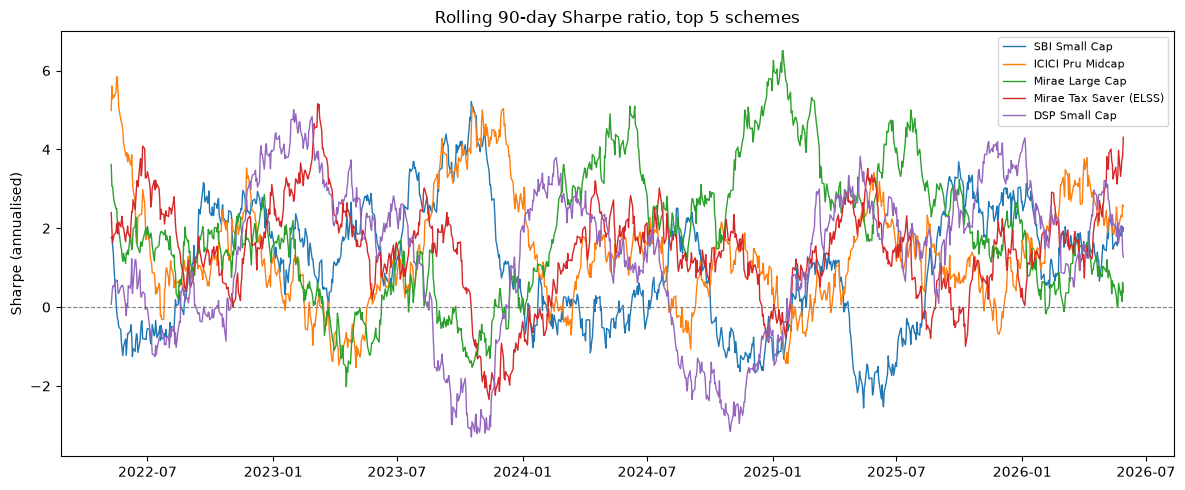

 amfi_code  var95_daily_pct  cvar95_daily_pct  max_drawdown_pct worst_drawdown_date  sharpe_annual  cagr_1y_pct  cagr_3y_pct  cagr_5y_pct
    100016            -1.44             -1.81            -24.73          2022-09-15          -0.20        -2.31         0.16          NaN
    100025            -0.38             -0.50             -4.31          2023-07-28          -0.57         2.85         4.77          NaN
    100033            -1.90             -2.35            -16.22          2022-05-12           1.09        48.42        33.76          NaN
    101206            -1.33             -1.74            -11.29          2023-07-05           1.03        44.94        32.73          NaN
    101207            -2.60             -3.25            -35.45          2026-05-11           0.16       -24.17        -3.16          NaN
    101208            -0.03             -0.04             -0.16          2023-09-12          -0.82         6.91         6.08          NaN
    102885            -1.26       

In [ ]:
import numpy as np

nav_s = nav.sort_values(["amfi_code", "date"]).copy()
nav_s["ret"] = nav_s.groupby("amfi_code")["nav"].pct_change()
RF = 0.065  # risk-free rate, RBI repo proxy (brief)

rows = []
for code, g in nav_s.groupby("amfi_code"):
    r = g["ret"].dropna()
    var95 = np.percentile(r, 5)
    cvar95 = r[r <= var95].mean()
    run_max = g["nav"].cummax()
    max_dd = (g["nav"] / run_max - 1).min()
    worst_dd_date = g.loc[(g["nav"] / run_max - 1).idxmin(), "date"]
    sharpe = (r.mean() * 252 - RF) / (r.std() * np.sqrt(252))
    rows.append({
        "amfi_code": code,
        "var95_daily_pct": round(var95 * 100, 3),
        "cvar95_daily_pct": round(cvar95 * 100, 3),
        "max_drawdown_pct": round(max_dd * 100, 2),
        "worst_drawdown_date": worst_dd_date.date(),
        "sharpe_annual": round(sharpe, 3),
    })

fund_metrics = pd.DataFrame(rows)

# Rolling CAGR: 252 trading days = 1 year, 756 = 3 years, 1260 = 5 years
for label, n in [("cagr_1y_pct", 252), ("cagr_3y_pct", 756), ("cagr_5y_pct", 1260)]:
    def roll_cagr(s, n=n):
        return ((s / s.shift(n)) ** (252 / n) - 1) * 100
    nav_s[label] = nav_s.groupby("amfi_code")["nav"].transform(roll_cagr)

latest = nav_s.groupby("amfi_code").tail(1)[["amfi_code", "cagr_1y_pct", "cagr_3y_pct", "cagr_5y_pct"]]
fund_metrics = fund_metrics.merge(latest, on="amfi_code").round(2)

# Rolling 90-day Sharpe for the 5 key funds
top5 = [119598, 120505, 148567, 148569, 149324]
fig, ax = plt.subplots(figsize=(12, 5))
for code in top5:
    g = nav_s[nav_s["amfi_code"] == code].set_index("date")
    roll = g["ret"].rolling(90).mean() / g["ret"].rolling(90).std() * np.sqrt(252)
    ax.plot(roll.index, roll, linewidth=1, label=names_map[code])
ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)
ax.set_title("Rolling 90-day Sharpe ratio, top 5 schemes")
ax.set_ylabel("Sharpe (annualised)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("reports/chart_17_rolling_sharpe.png", dpi=150)
plt.show()

fund_metrics.to_csv("reports/var_cvar_report.csv", index=False)
print(fund_metrics.head(10).to_string(index=False))
print("\nSaved: reports/var_cvar_report.csv and reports/chart_17_rolling_sharpe.png")

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

conn = sqlite3.connect("data/processed/bluestock_mf.db")
nav = pd.read_sql_query("""
    SELECT amfi_code, date, nav
    FROM fact_nav
    WHERE nav_filled = 0
""", conn, parse_dates=["date"])

names_map = {
    119598: "SBI Small Cap", 120505: "ICICI Pru Midcap",
    148567: "Mirae Large Cap", 148569: "Mirae Tax Saver (ELSS)",
    149324: "DSP Small Cap",
}
print(nav.shape)

(46000, 3)


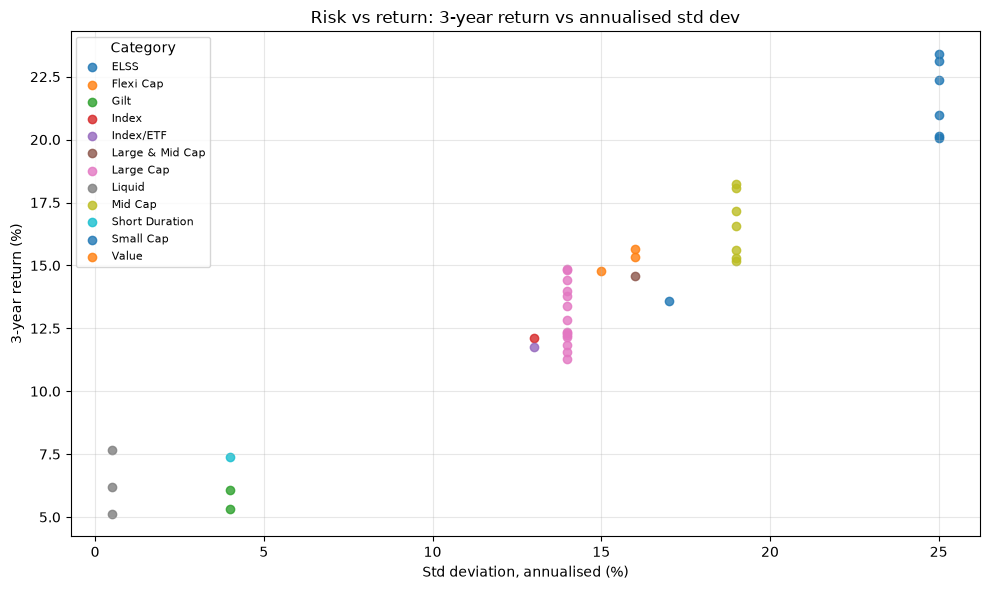

Schemes plotted: 40
                 std_dev_ann_pct  return_3yr_pct
category                                        
ELSS                        17.0            13.6
Flexi Cap                   16.0            15.5
Gilt                         4.0             5.7
Index                       13.0            12.1
Index/ETF                   13.0            11.8
Large & Mid Cap             16.0            14.6
Large Cap                   14.0            13.0
Liquid                       0.5             6.3
Mid Cap                     19.0            16.6
Short Duration               4.0             7.4
Small Cap                   25.0            21.7
Value                       15.0            14.8
Correlation (risk vs 3yr return): 0.96
Transaction types: {'SIP': 19716, 'Lumpsum': 8095, 'Redemption': 4967}
Rows: 32778 | unique investors: 5000


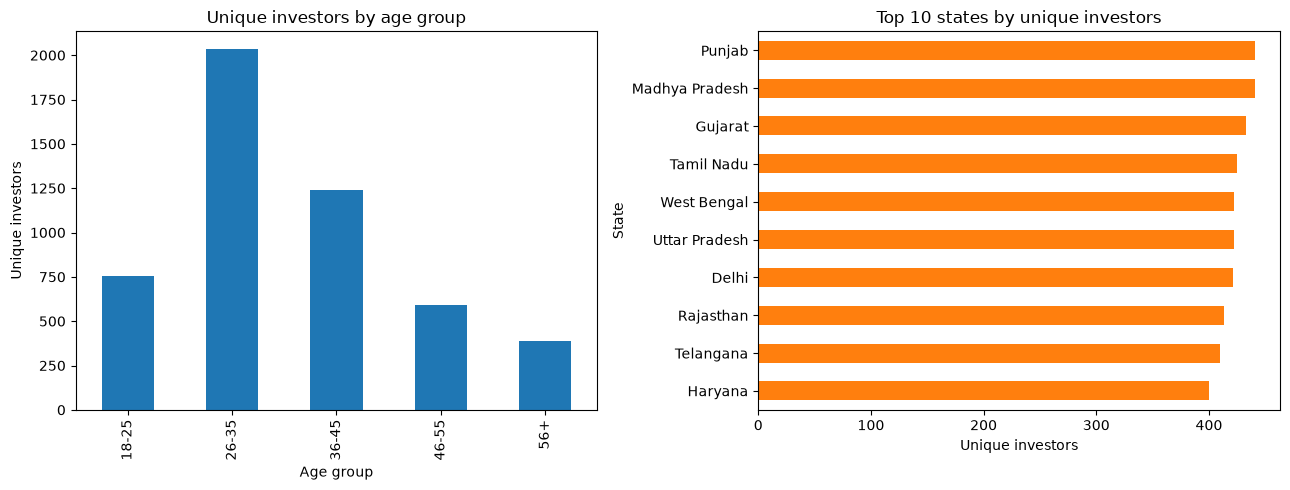

age_group
18-25    15.1
26-35    40.7
36-45    24.7
46-55    11.8
56+       7.8
state
Madhya Pradesh    441
Punjab            441
Gujarat           433
Tamil Nadu        425
Uttar Pradesh     422
West Bengal       422
Delhi             421
Rajasthan         413
Telangana         410
Haryana           400


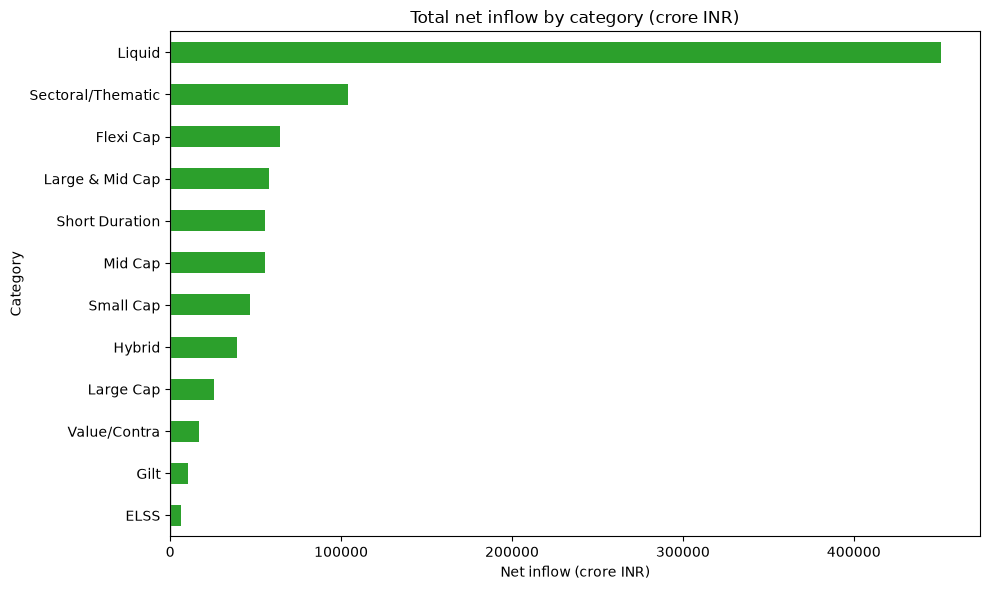

Period: 2024-04 to 2025-03
category
ELSS                   6080.0
Gilt                  10395.0
Value/Contra          16980.0
Large Cap             25633.0
Hybrid                38868.0
Small Cap             46596.0
Mid Cap               55312.0
Short Duration        55530.0
Large & Mid Cap       57752.0
Flexi Cap             63989.0
Sectoral/Thematic    103829.0
Liquid               451275.0


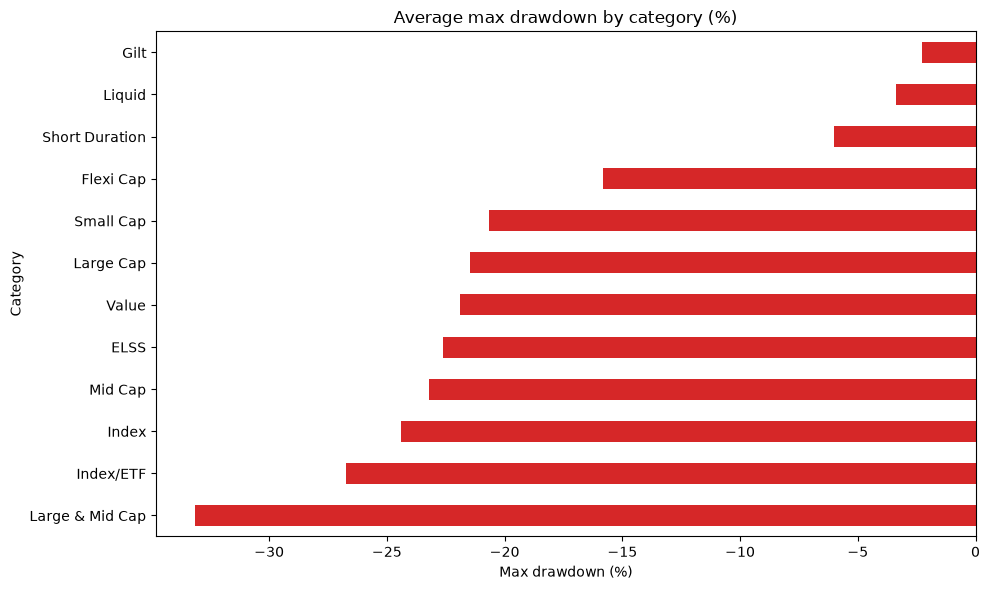

category
Large & Mid Cap   -33.2
Index/ETF         -26.8
Index             -24.4
Mid Cap           -23.2
ELSS              -22.6
Value             -21.9
Large Cap         -21.5
Small Cap         -20.7
Flexi Cap         -15.8
Short Duration     -6.0
Liquid             -3.4
Gilt               -2.3


In [ ]:
# Chart 13: risk vs return
perf = pd.read_csv(find_raw("performance"))
p = perf.dropna(subset=["std_dev_ann_pct", "return_3yr_pct"])
fig, ax = plt.subplots(figsize=(10, 6))
for cat, g in p.groupby("category"):
    ax.scatter(g["std_dev_ann_pct"], g["return_3yr_pct"], label=cat, alpha=0.8)
ax.set_title("Risk vs return: 3-year return vs annualised std dev")
ax.set_xlabel("Std deviation, annualised (%)")
ax.set_ylabel("3-year return (%)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, title="Category")
plt.tight_layout()
plt.savefig("reports/chart_13_risk_return.png", dpi=150)
plt.show()
print("Schemes plotted:", len(p))
print(p.groupby("category")[["std_dev_ann_pct", "return_3yr_pct"]].mean().round(1).to_string())
print("Correlation (risk vs 3yr return):", round(p["std_dev_ann_pct"].corr(p["return_3yr_pct"]), 2))

# Chart 14: investor demographics
inv = pd.read_csv(find_raw("investor"))
print("Transaction types:", inv["transaction_type"].value_counts().to_dict())
print("Rows:", len(inv), "| unique investors:", inv["investor_id"].nunique())

by_age = inv.groupby("age_group")["investor_id"].nunique()
by_state = inv.groupby("state")["investor_id"].nunique().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
by_age.plot(kind="bar", ax=axes[0], color="tab:blue")
axes[0].set_title("Unique investors by age group")
axes[0].set_xlabel("Age group")
axes[0].set_ylabel("Unique investors")
by_state.sort_values().plot(kind="barh", ax=axes[1], color="tab:orange")
axes[1].set_title("Top 10 states by unique investors")
axes[1].set_xlabel("Unique investors")
axes[1].set_ylabel("State")
plt.tight_layout()
plt.savefig("reports/chart_14_investor_demographics.png", dpi=150)
plt.show()
print((by_age / by_age.sum() * 100).round(1).to_string())
print(by_state.to_string())

# Chart 15: category net inflows
cat = pd.read_csv(find_raw("category_inflows"))
cat_tot = cat.groupby("category")["net_inflow_crore"].sum().sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
cat_tot.plot(kind="barh", ax=ax, color="tab:green")
ax.axvline(0, color="gray", linewidth=1)
ax.set_title("Total net inflow by category (crore INR)")
ax.set_xlabel("Net inflow (crore INR)")
ax.set_ylabel("Category")
plt.tight_layout()
plt.savefig("reports/chart_15_category_inflows.png", dpi=150)
plt.show()
print("Period:", cat["month"].min(), "to", cat["month"].max())
print(cat_tot.round(0).to_string())

# Chart 16: max drawdown by category
dd = perf.dropna(subset=["max_drawdown_pct"]).groupby("category")["max_drawdown_pct"].mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
dd.plot(kind="barh", ax=ax, color="tab:red")
ax.set_title("Average max drawdown by category (%)")
ax.set_xlabel("Max drawdown (%)")
ax.set_ylabel("Category")
plt.tight_layout()
plt.savefig("reports/chart_16_drawdown_by_category.png", dpi=150)
plt.show()
print(dd.round(1).to_string())

In [ ]:
for f in sorted(RAW.glob("*.csv")):
    d = pd.read_csv(f, nrows=2)
    print(f.name.split("-", 3)[-1], "->", d.columns.tolist())

08_investor_transactions.csv -> ['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status']
09_portfolio_holdings.csv -> ['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']
10_benchmark_indices.csv -> ['date', 'index_name', 'close_value']
01_fund_master.csv -> ['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']
02_nav_history.csv -> ['amfi_code', 'date', 'nav']
03_aum_by_fund_house.csv -> ['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes']
04_monthly_sip_inflows.csv -> ['month', 'sip_inflow_crore', 'active_sip_accounts_crore', 'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_p

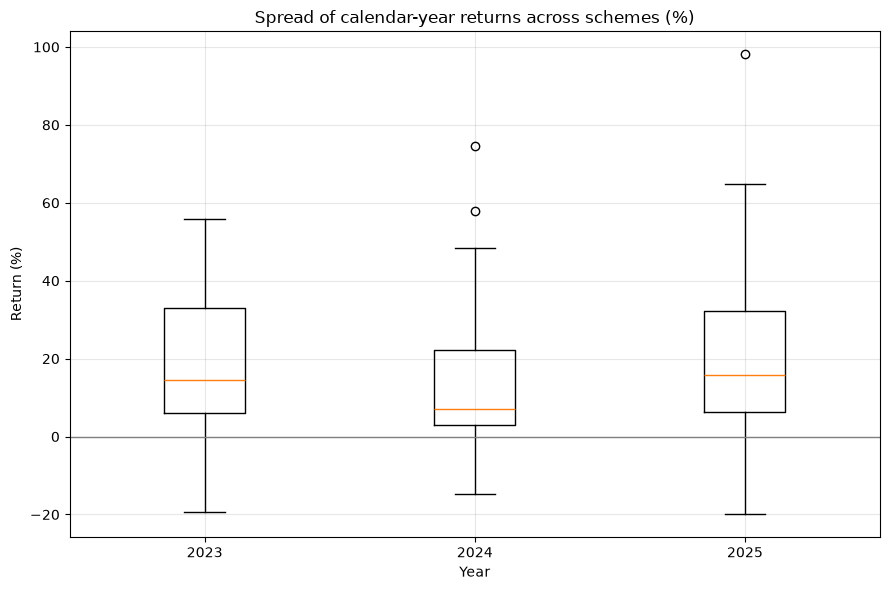

       2023  2024  2025
count  40.0  40.0  40.0
mean   19.2  13.7  19.7
std    19.3  20.8  21.9
min   -19.5 -14.8 -19.9
25%     5.9   2.9   6.3
50%    14.5   7.1  15.8
75%    33.1  22.2  32.2
max    55.7  74.6  98.1


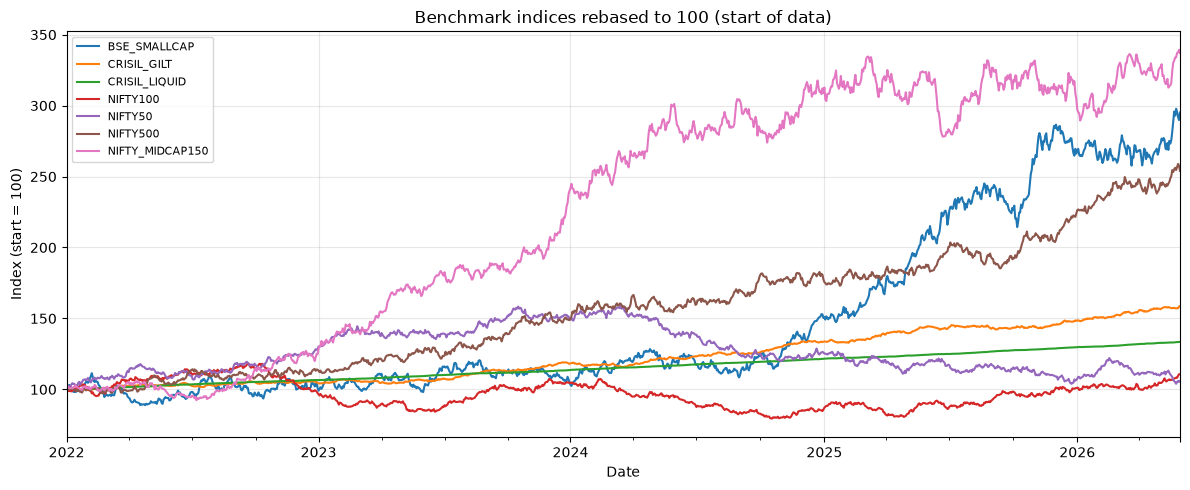

index_name
NIFTY_MIDCAP150    337.0
BSE_SMALLCAP       295.1
NIFTY500           254.0
CRISIL_GILT        158.7
CRISIL_LIQUID      133.5
NIFTY100           110.8
NIFTY50            105.9


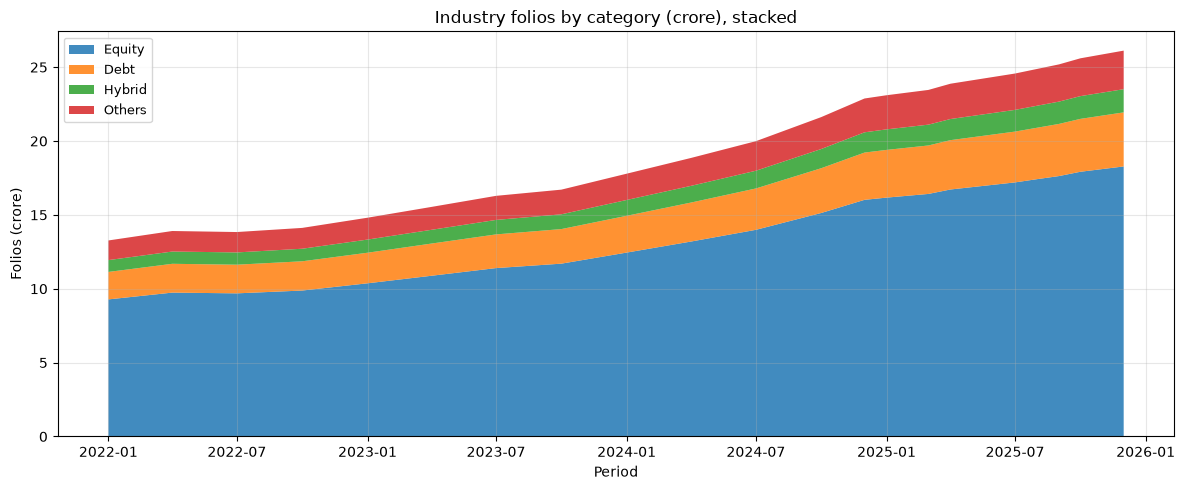

Equity share first/last (%): 70.0 70.0


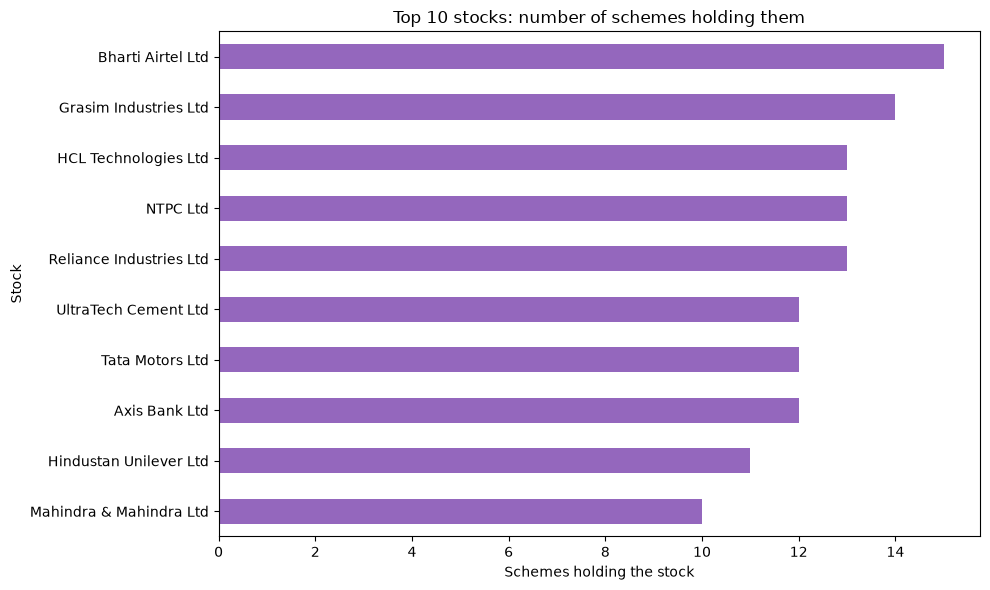

stock_name
Mahindra & Mahindra Ltd    10
Hindustan Unilever Ltd     11
Axis Bank Ltd              12
Tata Motors Ltd            12
UltraTech Cement Ltd       12
Reliance Industries Ltd    13
NTPC Ltd                   13
HCL Technologies Ltd       13
Grasim Industries Ltd      14
Bharti Airtel Ltd          15


In [ ]:
# Chart 9: spread of calendar-year returns across 40 schemes (box plot)
yr_rets = []
for year in [2023, 2024, 2025]:
    yr = nav_sorted[nav_sorted["date"].dt.year == year]
    r = (yr.groupby("amfi_code")["nav"].last() / yr.groupby("amfi_code")["nav"].first() - 1) * 100
    yr_rets.append(r.rename(year))
rets = pd.concat(yr_rets, axis=1)

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot([rets[y].dropna() for y in rets.columns])
ax.set_xticklabels([str(y) for y in rets.columns])
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("Spread of calendar-year returns across schemes (%)")
ax.set_xlabel("Year")
ax.set_ylabel("Return (%)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("reports/chart_09_return_spread.png", dpi=150)
plt.show()
print(rets.describe().round(1).to_string())

# Chart 10: all benchmark indices rebased to 100
b = bench.copy()
b["date"] = pd.to_datetime(b["date"])
piv = b.pivot_table(index="date", columns="index_name", values="close_value")
reb = piv / piv.apply(lambda s: s.dropna().iloc[0]) * 100

fig, ax = plt.subplots(figsize=(12, 5))
reb.plot(ax=ax, linewidth=1.5)
ax.set_title("Benchmark indices rebased to 100 (start of data)")
ax.set_xlabel("Date")
ax.set_ylabel("Index (start = 100)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("reports/chart_10_benchmarks_rebased.png", dpi=150)
plt.show()
print(reb.ffill().iloc[-1].round(1).sort_values(ascending=False).to_string())

# Chart 11: folio composition by category (stacked area)
f = folio.copy()
f["month"] = pd.to_datetime(f["month"])
f = f.sort_values("month")
cols = ["equity_folios_crore", "debt_folios_crore", "hybrid_folios_crore", "others_folios_crore"]

fig, ax = plt.subplots(figsize=(12, 5))
ax.stackplot(f["month"], [f[c] for c in cols], labels=["Equity", "Debt", "Hybrid", "Others"], alpha=0.85)
ax.set_title("Industry folios by category (crore), stacked")
ax.set_xlabel("Period")
ax.set_ylabel("Folios (crore)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("reports/chart_11_folio_composition.png", dpi=150)
plt.show()
print("Equity share first/last (%):",
      round(f.iloc[0]["equity_folios_crore"] / f.iloc[0]["total_folios_crore"] * 100, 1),
      round(f.iloc[-1]["equity_folios_crore"] / f.iloc[-1]["total_folios_crore"] * 100, 1))

# Chart 12: number of schemes holding each top-10 stock
t10 = stock.head(10).sort_values("funds_holding")
fig, ax = plt.subplots(figsize=(10, 6))
t10["funds_holding"].plot(kind="barh", ax=ax, color="tab:purple")
ax.set_title("Top 10 stocks: number of schemes holding them")
ax.set_xlabel("Schemes holding the stock")
ax.set_ylabel("Stock")
plt.tight_layout()
plt.savefig("reports/chart_12_stock_popularity.png", dpi=150)
plt.show()
print(t10["funds_holding"].to_string())

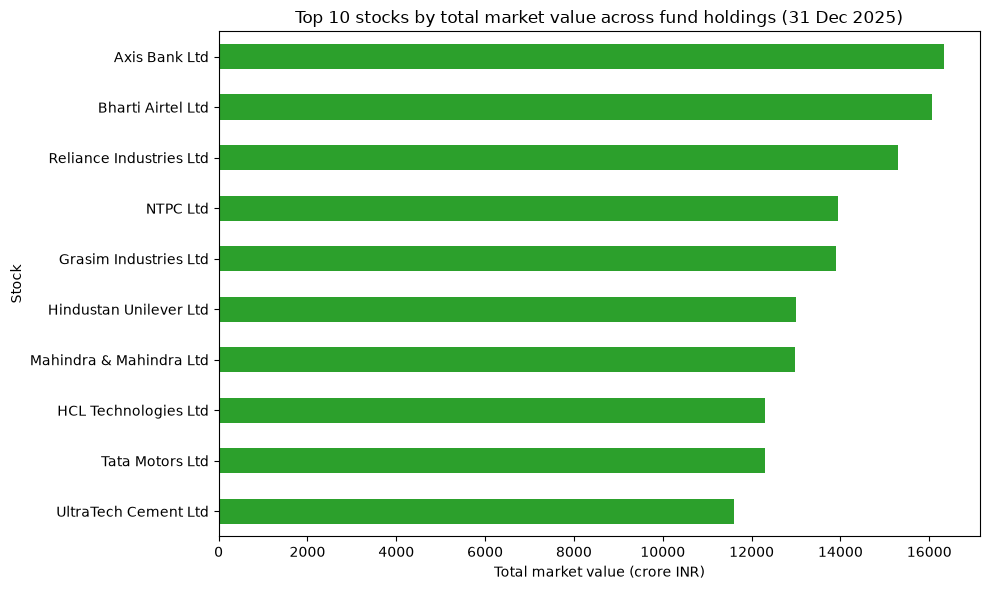

                         total_value_cr  funds_holding  share_pct
stock_name                                                       
Axis Bank Ltd                   16325.9             12        5.0
Bharti Airtel Ltd               16051.4             15        4.9
Reliance Industries Ltd         15286.5             13        4.7
NTPC Ltd                        13951.4             13        4.3
Grasim Industries Ltd           13897.8             14        4.3
Hindustan Unilever Ltd          12993.9             11        4.0
Mahindra & Mahindra Ltd         12967.3             10        4.0
HCL Technologies Ltd            12299.9             13        3.8
Tata Motors Ltd                 12296.8             12        3.8
UltraTech Cement Ltd            11612.0             12        3.6
Top 10 combined share (%): 42.4
Unique stocks: 30


In [ ]:
stock = (hold.groupby("stock_name")
             .agg(total_value_cr=("market_value_cr", "sum"),
                  funds_holding=("amfi_code", "nunique"))
             .sort_values("total_value_cr", ascending=False))
top10 = stock.head(10)
share10 = (top10["total_value_cr"] / stock["total_value_cr"].sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 6))
top10["total_value_cr"].sort_values().plot(kind="barh", ax=ax, color="tab:green")
ax.set_title("Top 10 stocks by total market value across fund holdings (31 Dec 2025)")
ax.set_xlabel("Total market value (crore INR)")
ax.set_ylabel("Stock")
plt.tight_layout()
plt.savefig("reports/chart_08_top_stocks.png", dpi=150)
plt.show()

print(top10.assign(share_pct=share10).round(1).to_string())
print("Top 10 combined share (%):", share10.sum().round(1))
print("Unique stocks:", len(stock))


1788499982117-e3d6ab98-09_portfolio_holdings.csv (322, 8)


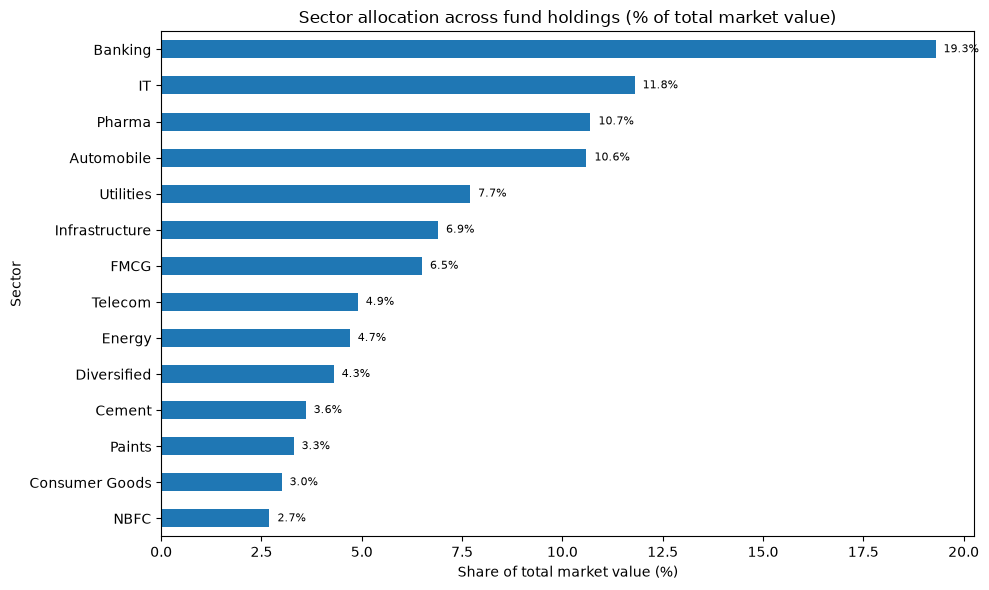

Portfolio date(s): <StringArray>
['2025-12-31']
Length: 1, dtype: str
sector
Banking           19.3
IT                11.8
Pharma            10.7
Automobile        10.6
Utilities          7.7
Infrastructure     6.9
FMCG               6.5
Telecom            4.9
Energy             4.7
Diversified        4.3
Cement             3.6
Paints             3.3
Consumer Goods     3.0
NBFC               2.7


In [ ]:
hold = pd.read_csv(find_raw("portfolio"))
print(find_raw("portfolio").name, hold.shape)

sec = (hold.groupby("sector")["market_value_cr"].sum()
           .sort_values(ascending=False))
share = (sec / sec.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 6))
share.sort_values().plot(kind="barh", ax=ax, color="tab:blue")
ax.set_title("Sector allocation across fund holdings (% of total market value)")
ax.set_xlabel("Share of total market value (%)")
ax.set_ylabel("Sector")
for i, v in enumerate(share.sort_values()):
    ax.text(v + 0.2, i, f"{v}%", va="center", fontsize=8)
plt.tight_layout()
plt.savefig("reports/chart_07_sector_allocation.png", dpi=150)
plt.show()

print("Portfolio date(s):", hold["portfolio_date"].unique())
print(share.to_string())

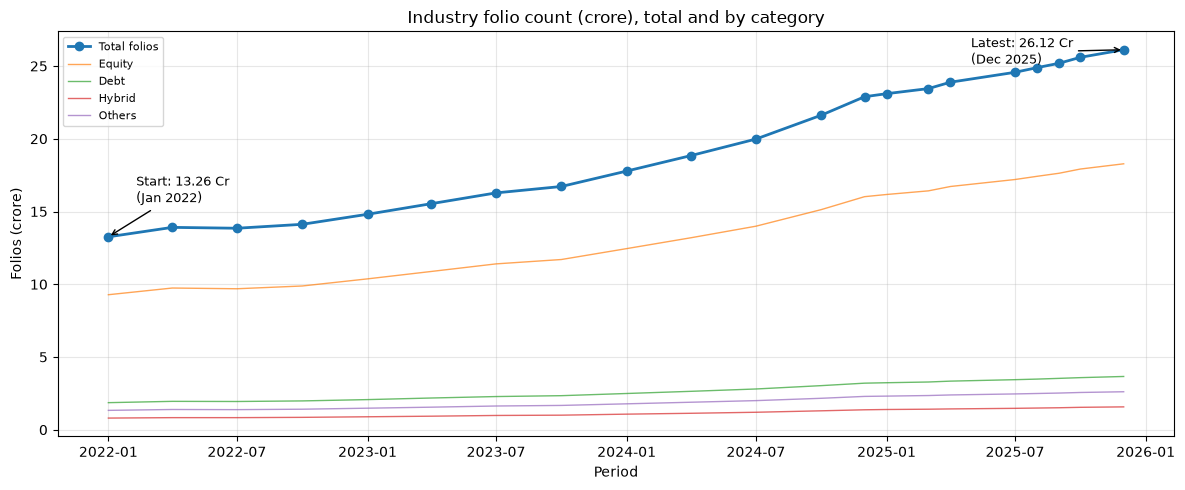

Rows: 21
First: 2022-01-01 -> 13.26
Last: 2025-12-01 -> 26.12
Peak: 2025-12-01 -> 26.12
     month  total_folios_crore  equity_folios_crore  debt_folios_crore  hybrid_folios_crore  others_folios_crore
2025-07-01               24.57                17.20               3.44                 1.47                 2.46
2025-08-01               24.89                17.42               3.48                 1.49                 2.49
2025-09-01               25.19                17.63               3.53                 1.51                 2.52
2025-10-01               25.60                17.92               3.58                 1.54                 2.56
2025-12-01               26.12                18.28               3.66                 1.57                 2.61


In [ ]:
folio["month"] = pd.to_datetime(folio["month"])
folio = folio.sort_values("month").reset_index(drop=True)

first, last = folio.iloc[0], folio.iloc[-1]
peak = folio.loc[folio["total_folios_crore"].idxmax()]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(folio["month"], folio["total_folios_crore"], marker="o", linewidth=2, label="Total folios")
for col, lab in [("equity_folios_crore", "Equity"), ("debt_folios_crore", "Debt"),
                 ("hybrid_folios_crore", "Hybrid"), ("others_folios_crore", "Others")]:
    ax.plot(folio["month"], folio[col], linewidth=1, alpha=0.7, label=lab)

ax.annotate(f"Start: {first['total_folios_crore']:.2f} Cr\n({first['month']:%b %Y})",
            xy=(first["month"], first["total_folios_crore"]),
            xytext=(20, 25), textcoords="offset points",
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.annotate(f"Latest: {last['total_folios_crore']:.2f} Cr\n({last['month']:%b %Y})",
            xy=(last["month"], last["total_folios_crore"]),
            xytext=(-110, -10), textcoords="offset points",
            arrowprops=dict(arrowstyle="->"), fontsize=9)

ax.set_title("Industry folio count (crore), total and by category")
ax.set_xlabel("Period")
ax.set_ylabel("Folios (crore)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig("reports/chart_06_folio_growth.png", dpi=150)
plt.show()

print("Rows:", len(folio))
print("First:", first["month"].date(), "->", first["total_folios_crore"])
print("Last:", last["month"].date(), "->", last["total_folios_crore"])
print("Peak:", peak["month"].date(), "->", peak["total_folios_crore"])
print(folio.tail(5).to_string(index=False))

In [ ]:
print([f.name for f in RAW.glob("*.csv")])

['1788499980509-304c1255-08_investor_transactions.csv', '1788499982117-e3d6ab98-09_portfolio_holdings.csv', '1788499982615-f9647ab2-10_benchmark_indices.csv', '1788499983024-b042c300-01_fund_master.csv', '1788499983331-4389156d-02_nav_history.csv', '1788499984134-b0cbf625-03_aum_by_fund_house.csv', '1788499984405-d702a6c6-04_monthly_sip_inflows.csv', '1788499984721-4b860901-05_category_inflows.csv', '1788499985036-da4a0c4a-06_industry_folio_count.csv', '1788499985420-bb134abf-07_scheme_performance.csv', 'nav_axis_bluechip_119092.csv', 'nav_hdfc_top100_direct_125497.csv', 'nav_icici_bluechip_120503.csv', 'nav_kotak_bluechip_120841.csv', 'nav_nippon_large_cap_118632.csv', 'nav_sbi_bluechip_119551.csv']


In [ ]:
folio = pd.read_csv(find_raw("industry_folio"))
print(find_raw("industry_folio").name)
print(folio.shape)
print(folio.columns.tolist())
print(folio.head(3).to_string())

1788499985036-da4a0c4a-06_industry_folio_count.csv
(21, 6)
['month', 'total_folios_crore', 'equity_folios_crore', 'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore']
     month  total_folios_crore  equity_folios_crore  debt_folios_crore  hybrid_folios_crore  others_folios_crore
0  2022-01               13.26                 9.28               1.86                 0.80                 1.33
1  2022-04               13.91                 9.74               1.95                 0.83                 1.39
2  2022-07               13.85                 9.69               1.94                 0.83                 1.38


In [ ]:
from pathlib import Path
RAW = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")

def find_raw(keyword):
    return [f for f in RAW.glob("*.csv") if keyword in f.name.lower()][0]

folio = pd.read_csv(find_raw("folio"))
print(folio.shape)
print(folio.columns.tolist())
print(folio.head(3).to_string())

(322, 8)
['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']
   amfi_code stock_symbol              stock_name       sector  weight_pct  market_value_cr  current_price_inr portfolio_date
0     119551    POWERGRID  Power Grid Corporation    Utilities       13.85           737.09            6011.08     2025-12-31
1     119551     HDFCBANK           HDFC Bank Ltd      Banking       11.19            88.97            1074.65     2025-12-31
2     119551       GRASIM   Grasim Industries Ltd  Diversified        9.90           208.45            5964.59     2025-12-31


In [ ]:
folio = pd.read_csv(find_raw("folio"))
print(folio.shape)
print(folio.columns.tolist())
print(folio.head(3).to_string())

(322, 8)
['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']
   amfi_code stock_symbol              stock_name       sector  weight_pct  market_value_cr  current_price_inr portfolio_date
0     119551    POWERGRID  Power Grid Corporation    Utilities       13.85           737.09            6011.08     2025-12-31
1     119551     HDFCBANK           HDFC Bank Ltd      Banking       11.19            88.97            1074.65     2025-12-31
2     119551       GRASIM   Grasim Industries Ltd  Diversified        9.90           208.45            5964.59     2025-12-31


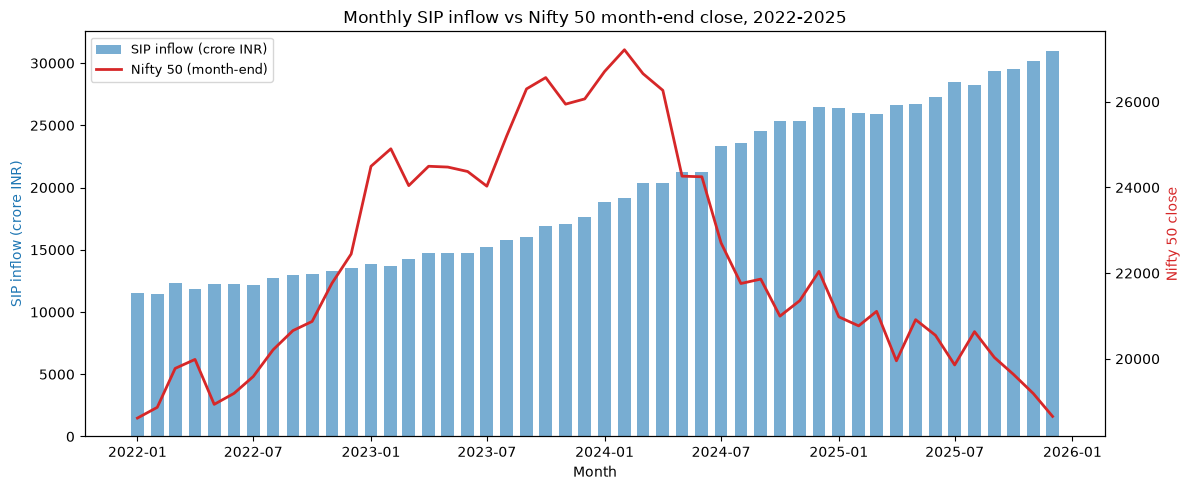

Matched months: 48
Correlation (SIP vs Nifty): -0.211


In [ ]:
nifty = bench[bench["index_name"] == "NIFTY50"].copy()
nifty["month"] = pd.to_datetime(nifty["date"]).dt.to_period("M").dt.to_timestamp()
nifty_m = nifty.groupby("month")["close_value"].last().reset_index()

sip_m = sip.copy()
sip_m["month"] = pd.to_datetime(sip_m["sip_month"]).dt.to_period("M").dt.to_timestamp()
merged = sip_m.merge(nifty_m, on="month", how="inner")

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(merged["month"], merged["sip_inflow_crore"], width=20, color="tab:blue", alpha=0.6, label="SIP inflow (crore INR)")
ax1.set_xlabel("Month")
ax1.set_ylabel("SIP inflow (crore INR)", color="tab:blue")

ax2 = ax1.twinx()
ax2.plot(merged["month"], merged["close_value"], color="tab:red", linewidth=2, label="Nifty 50 (month-end)")
ax2.set_ylabel("Nifty 50 close", color="tab:red")

ax1.set_title("Monthly SIP inflow vs Nifty 50 month-end close, 2022-2025")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("reports/chart_05_sip_vs_nifty.png", dpi=150)
plt.show()

print("Matched months:", len(merged))
print("Correlation (SIP vs Nifty):", round(merged["sip_inflow_crore"].corr(merged["close_value"]), 3))

In [ ]:
bench = pd.read_csv(find_raw("benchmark"))
print(bench.shape)
print(bench.columns.tolist())
print(bench.head(3).to_string())

(8050, 3)
['date', 'index_name', 'close_value']
         date index_name  close_value
0  2022-01-03    NIFTY50     17492.79
1  2022-01-04    NIFTY50     17689.64
2  2022-01-05    NIFTY50     17835.05


In [ ]:
from pathlib import Path
RAW = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")

def find_raw(keyword):
    return [f for f in RAW.glob("*.csv") if keyword in f.name.lower()][0]

In [ ]:
bench = pd.read_csv(find_raw("benchmark"))
print(bench.shape)
print(bench.columns.tolist())
print(bench.head(3).to_string())

NameError: name 'find_raw' is not defined

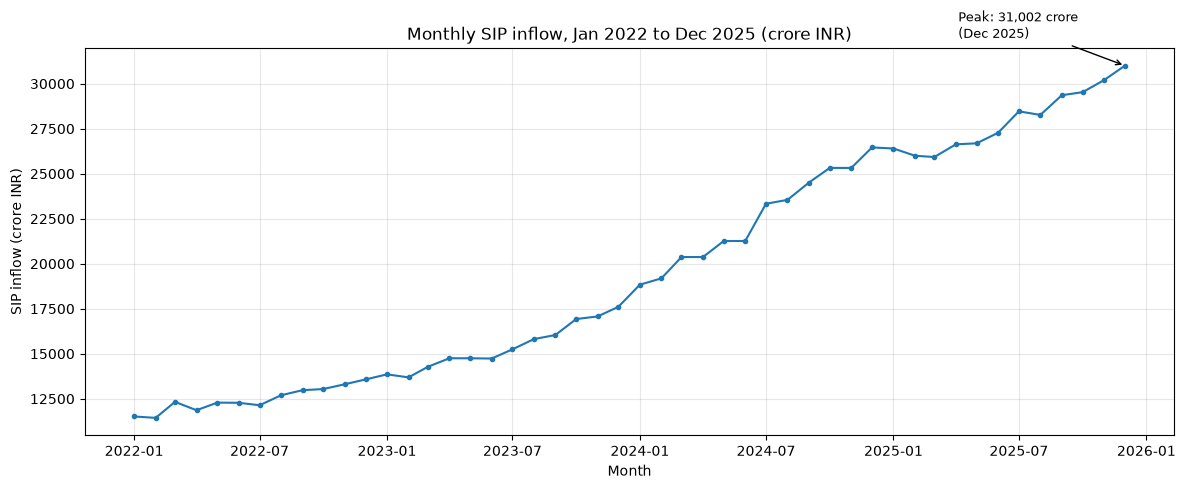

Peak month: 2025-12 -> 31002.0
First month: 2022-01 -> 11517.0
Last month: 2025-12 -> 31002.0


In [ ]:
sip = pd.read_sql_query("""
    SELECT sip_month, sip_inflow_crore
    FROM fact_sip
    ORDER BY sip_month
""", conn)
sip["month"] = pd.to_datetime(sip["sip_month"])

peak = sip.loc[sip["sip_inflow_crore"].idxmax()]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(sip["month"], sip["sip_inflow_crore"], marker="o", markersize=3, linewidth=1.5)
ax.annotate(
    f"Peak: {peak['sip_inflow_crore']:,.0f} crore\n({peak['month']:%b %Y})",
    xy=(peak["month"], peak["sip_inflow_crore"]),
    xytext=(-120, 20), textcoords="offset points",
    arrowprops=dict(arrowstyle="->"), fontsize=9,
)
ax.set_title("Monthly SIP inflow, Jan 2022 to Dec 2025 (crore INR)")
ax.set_xlabel("Month")
ax.set_ylabel("SIP inflow (crore INR)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("reports/chart_04_sip_inflow.png", dpi=150)
plt.show()

print("Peak month:", peak["sip_month"], "->", peak["sip_inflow_crore"])
print("First month:", sip.iloc[0]["sip_month"], "->", sip.iloc[0]["sip_inflow_crore"])
print("Last month:", sip.iloc[-1]["sip_month"], "->", sip.iloc[-1]["sip_inflow_crore"])

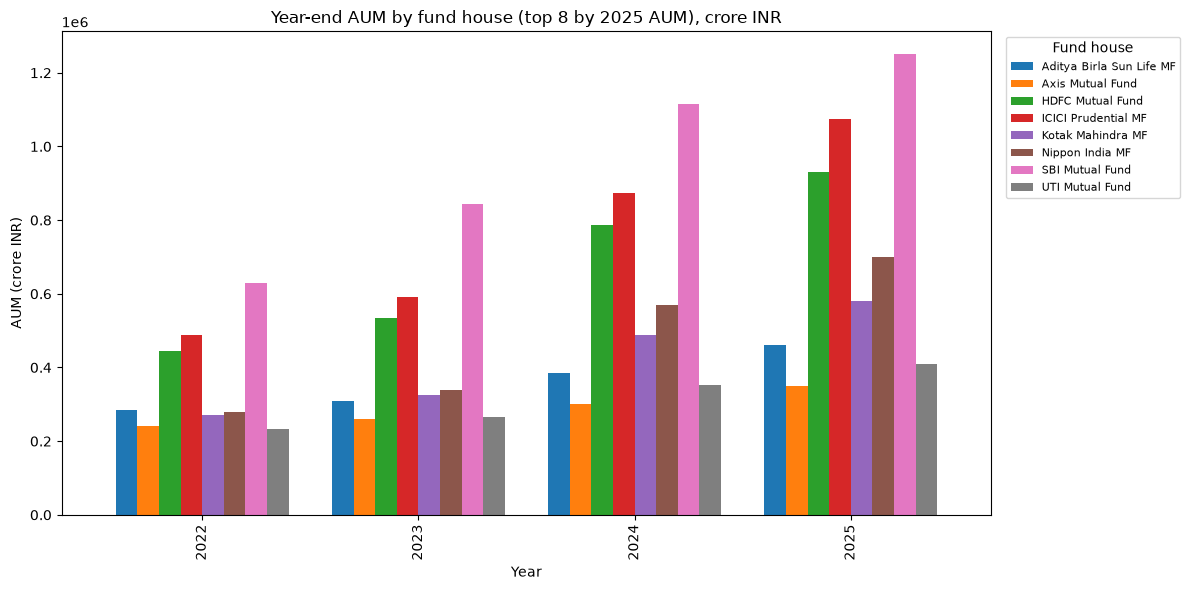

fund_house  Aditya Birla Sun Life MF  Axis Mutual Fund  HDFC Mutual Fund  ICICI Prudential MF  Kotak Mahindra MF  Nippon India MF  SBI Mutual Fund  UTI Mutual Fund
year                                                                                                                                                               
2022                        285000.0          240000.0          445000.0             488000.0           272000.0         278000.0         630000.0         232000.0
2023                        308000.0          260000.0          535000.0             590000.0           325000.0         340000.0         845000.0         265000.0
2024                        384000.0          300000.0          787000.0             874000.0           489000.0         570000.0        1114000.0         352000.0
2025                        460000.0          350000.0          930000.0            1074000.0           580000.0         700000.0        1250000.0         410000.0


In [ ]:
aum = pd.read_sql_query("""
    SELECT date, fund_house, aum_crore
    FROM fact_aum
""", conn, parse_dates=["date"])

aum["year"] = aum["date"].dt.year
year_end = (aum.sort_values("date")
               .groupby(["year", "fund_house"])
               .tail(1))

top_houses = (year_end[year_end["year"] == 2025]
              .nlargest(8, "aum_crore")["fund_house"])
pivot = (year_end[year_end["fund_house"].isin(top_houses)]
         .pivot(index="year", columns="fund_house", values="aum_crore"))

ax = pivot.plot(kind="bar", figsize=(12, 6), width=0.8)
ax.set_title("Year-end AUM by fund house (top 8 by 2025 AUM), crore INR")
ax.set_xlabel("Year")
ax.set_ylabel("AUM (crore INR)")
ax.legend(title="Fund house", fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("reports/chart_03_aum_growth.png", dpi=150)
plt.show()

print(pivot.round(0).to_string())

In [ ]:
nav_sorted = nav.sort_values(["amfi_code", "date"])
yearly = []
for year in [2022, 2023, 2024, 2025, 2026]:
    yr = nav_sorted[nav_sorted["date"].dt.year == year]
    start = yr.groupby("amfi_code")["nav"].first()
    end = yr.groupby("amfi_code")["nav"].last()
    ret = (end / start - 1) * 100
    yearly.append({"year": year, "avg_return_pct": round(ret.mean(), 2),
                   "median_return_pct": round(ret.median(), 2),
                   "funds_positive": int((ret > 0).sum()), "funds_total": len(ret)})
yearly_df = pd.DataFrame(yearly)
print(yearly_df.to_string(index=False))

top5 = [119598, 120505, 148567, 148569, 149324]
top_ret = nav_sorted[nav_sorted["amfi_code"].isin(top5)]
print("\nTop 5 funds, calendar-year return (%):")
print(
    top_ret.groupby(["amfi_code", top_ret["date"].dt.year])["nav"]
    .agg(lambda s: round((s.iloc[-1] / s.iloc[0] - 1) * 100, 2))
    .unstack()
    .rename(index=names_map)
    .to_string()
)

 year  avg_return_pct  median_return_pct  funds_positive  funds_total
 2022           18.08              14.44              34           40
 2023           19.18              14.54              33           40
 2024           13.69               7.12              31           40
 2025           19.66              15.81              35           40
 2026            7.34               6.56              29           40

Top 5 funds, calendar-year return (%):
date                     2022   2023   2024   2025   2026
amfi_code                                                
SBI Small Cap           45.31  52.80   5.13  27.52  18.92
ICICI Pru Midcap        53.64  34.34   5.74  36.79  15.53
Mirae Large Cap         36.22  -3.09  74.56  41.07  -3.29
Mirae Tax Saver (ELSS)  45.41  19.82  19.22  18.93  36.40
DSP Small Cap           35.56  32.52 -14.85  98.11  10.15


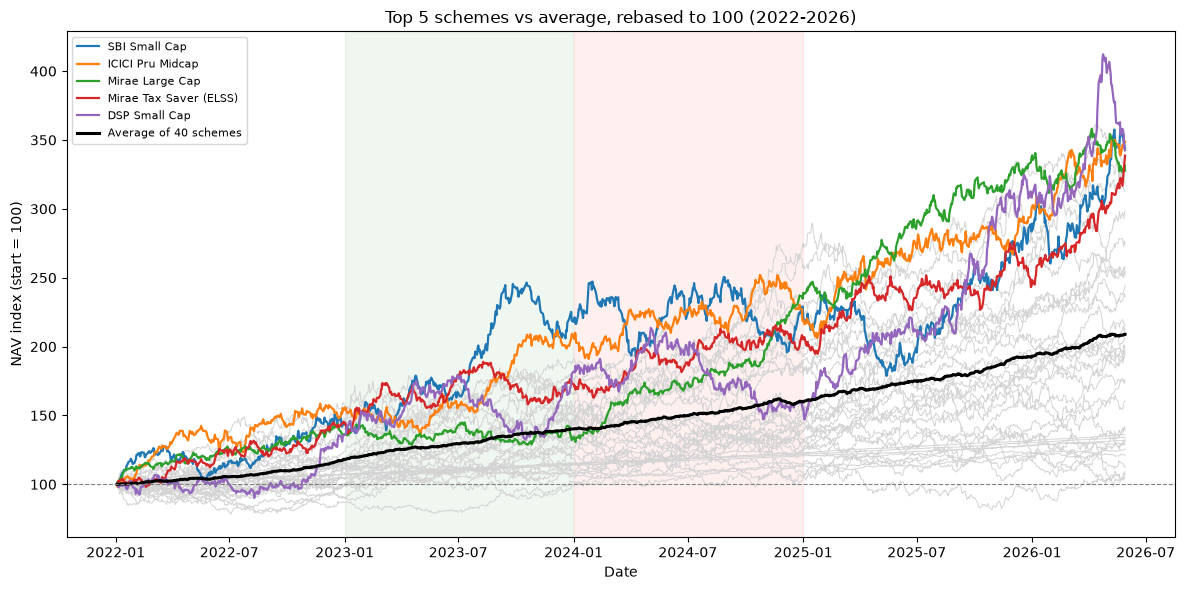

In [ ]:
names_map = {
    119598: "SBI Small Cap", 120505: "ICICI Pru Midcap",
    148567: "Mirae Large Cap", 148569: "Mirae Tax Saver (ELSS)",
    149324: "DSP Small Cap",
}
avg = nav.groupby("date")["nav_index"].mean()

fig, ax = plt.subplots(figsize=(12, 6))
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31"), color="green", alpha=0.06)
ax.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31"), color="red", alpha=0.06)

for code, g in nav.groupby("amfi_code"):
    if code not in names_map:
        ax.plot(g["date"], g["nav_index"], color="lightgrey", linewidth=0.7)

for code, label in names_map.items():
    g = nav[nav["amfi_code"] == code]
    ax.plot(g["date"], g["nav_index"], linewidth=1.6, label=label)

ax.plot(avg.index, avg.values, color="black", linewidth=2.2, label="Average of 40 schemes")
ax.axhline(100, color="grey", linestyle="--", linewidth=0.8)
ax.set_title("Top 5 schemes vs average, rebased to 100 (2022-2026)")
ax.set_xlabel("Date")
ax.set_ylabel("NAV index (start = 100)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("reports/chart_02_top5_highlight.png", dpi=150)
plt.show()

In [ ]:
names = pd.read_sql_query("""
    SELECT amfi_code, scheme_name, category, sub_category
    FROM dim_fund
    WHERE amfi_code IN (149324, 148569, 148567, 120505, 119598)
""", conn)
print(names.to_string(index=False))

 amfi_code                                   scheme_name category sub_category
    119598    SBI Small Cap Fund - Regular Plan - Growth   Equity    Small Cap
    120505      ICICI Pru Midcap Fund - Regular - Growth   Equity      Mid Cap
    148567 Mirae Asset Large Cap Fund - Regular - Growth   Equity    Large Cap
    148569 Mirae Asset Tax Saver Fund - Regular - Growth   Equity         ELSS
    149324         DSP Small Cap Fund - Regular - Growth   Equity    Small Cap


In [ ]:
final = nav.sort_values("date").groupby("amfi_code").tail(1)
top = final.sort_values("nav_index", ascending=False).head(5)
print(top[["amfi_code", "date", "nav_index"]])

       amfi_code       date   nav_index
29899     120505 2026-05-29  348.684056
25299     119598 2026-05-29  344.043537
45999     149324 2026-05-29  342.490579
42549     148569 2026-05-29  338.658097
40249     148567 2026-05-29  327.781083


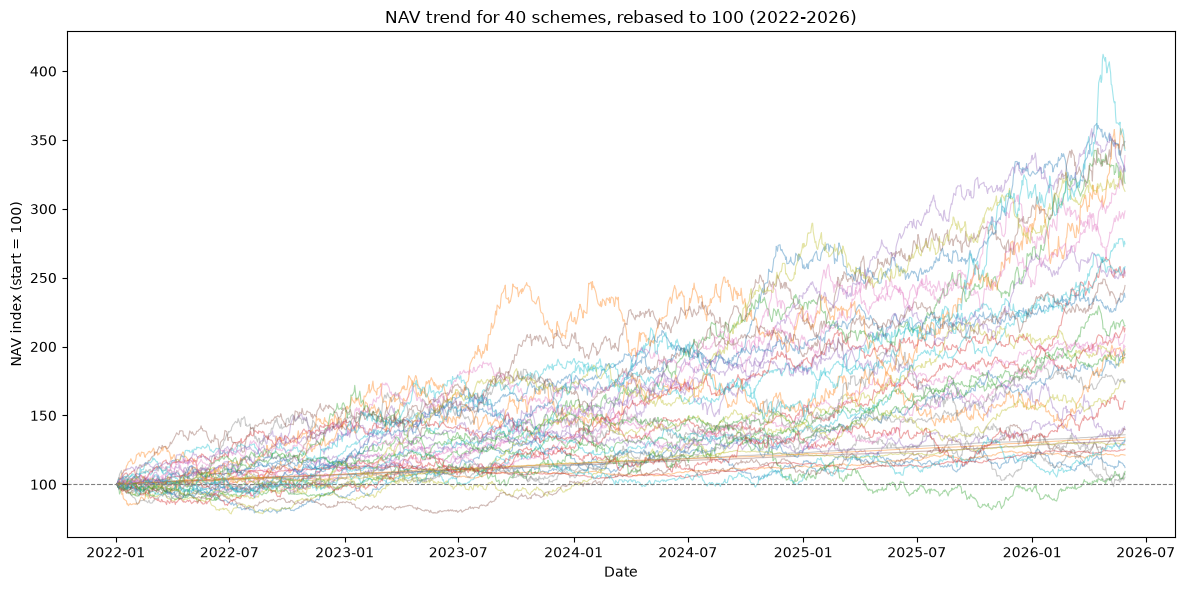

In [ ]:
nav["nav_index"] = nav.groupby("amfi_code")["nav"].transform(lambda s: s / s.iloc[0] * 100)

fig, ax = plt.subplots(figsize=(12, 6))
for code, g in nav.groupby("amfi_code"):
    ax.plot(g["date"], g["nav_index"], linewidth=0.8, alpha=0.4)

ax.set_title("NAV trend for 40 schemes, rebased to 100 (2022-2026)")
ax.set_xlabel("Date")
ax.set_ylabel("NAV index (start = 100)")
ax.axhline(100, color="grey", linestyle="--", linewidth=0.8)
plt.tight_layout()
plt.savefig("reports/chart_01_nav_trend.png", dpi=150)
plt.show()

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("data/processed/bluestock_mf.db")
nav = pd.read_sql_query("""
    SELECT n.amfi_code, n.date, n.nav
    FROM fact_nav n
    WHERE n.nav_filled = 0
""", conn, parse_dates=["date"])
print(nav.shape)
nav.head()

(46000, 3)


,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639
